<a href="https://colab.research.google.com/github/2403a51078-code/AIDL_LAB_ASSIGNMENTS/blob/main/adil_lab19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 16.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 403kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.69MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.28MB/s]


Training samples: 54000
Validation samples: 6000

Generator Architecture:
Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=6272, bias=True)
    (1): BatchNorm1d(6272, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Unflatten(dim=1, unflattened_size=(128, 7, 7))
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Tanh()
  )
)

Discriminator Architecture:
Discriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affi

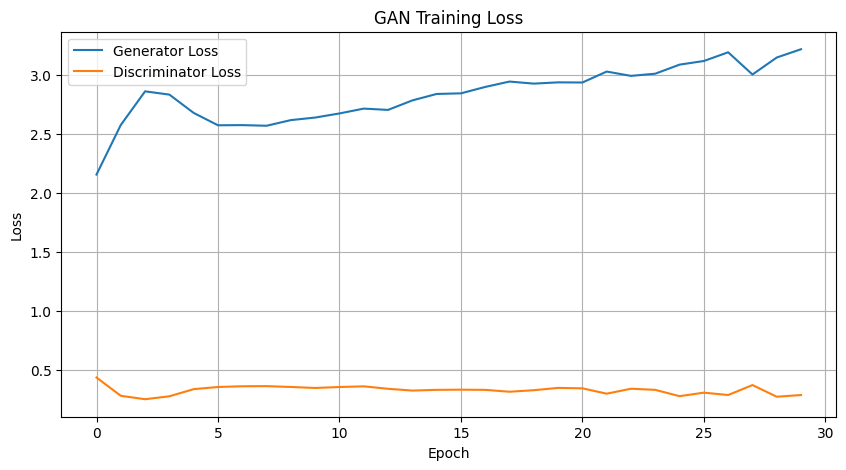

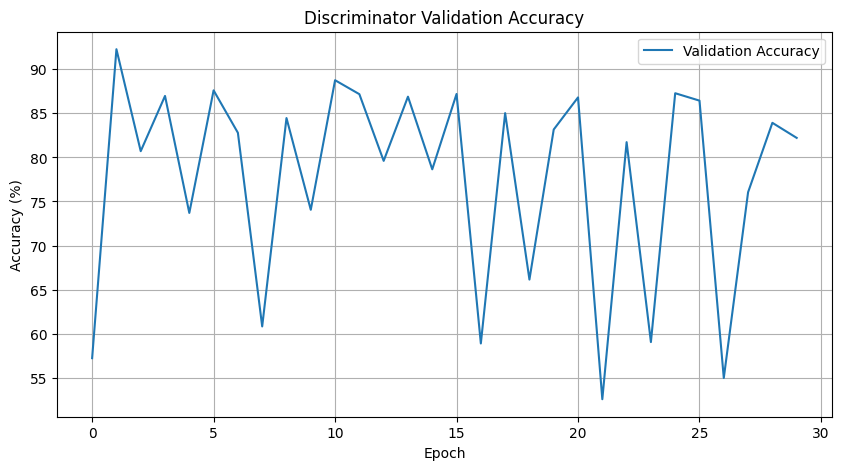

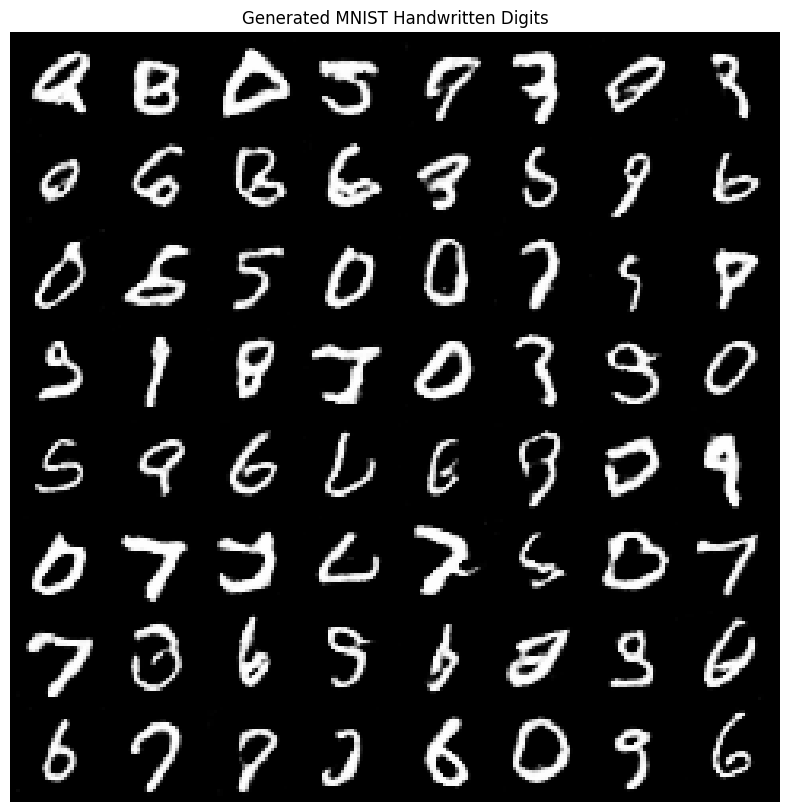


========== FINAL RESULTS ==========
Dataset: MNIST
Model: DCGAN
Epochs: 30
Generator Loss: 3.2208
Discriminator Loss: 0.2861
Validation Discriminator Accuracy: 82.22 %
Generated Images: 64
Output Folder: gan_results

GAN TRAINING COMPLETED SUCCESSFULLY!


In [ ]:

# ============================================================
# LAB / EXPERIMENT 19
# GENERATIVE ADVERSARIAL NETWORKS (GAN) FOR IMAGE GENERATION
# Dataset: MNIST Handwritten Digits
# Framework: PyTorch
# ============================================================

# STEP 1: IMPORT LIBRARIES

import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import save_image, make_grid


# STEP 2: CONFIGURATION

SEED = 42
BATCH_SIZE = 128
LATENT_DIM = 100
EPOCHS = 30
LEARNING_RATE = 0.0002
BETA1 = 0.5

OUTPUT_DIR = "gan_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# STEP 3: DOWNLOAD AND PREPROCESS MNIST DATASET

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Split dataset into training and validation sets

train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))


# STEP 4: CREATE GENERATOR NETWORK

class Generator(nn.Module):

    def __init__(self):
        super(Generator, self).__init__()

        self.model = nn.Sequential(

            nn.Linear(LATENT_DIM, 128 * 7 * 7),

            nn.BatchNorm1d(128 * 7 * 7),

            nn.ReLU(True),

            nn.Unflatten(1, (128, 7, 7)),

            nn.ConvTranspose2d(
                128, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(True),

            nn.ConvTranspose2d(
                64, 1,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            nn.Tanh()
        )

    def forward(self, z):
        return self.model(z)


# STEP 5: CREATE DISCRIMINATOR NETWORK

class Discriminator(nn.Module):

    def __init__(self):
        super(Discriminator, self).__init__()

        self.model = nn.Sequential(

            nn.Conv2d(
                1, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),

            nn.Linear(128 * 7 * 7, 1)
        )

    def forward(self, image):
        return self.model(image)


# STEP 6: INITIALIZE MODELS

generator = Generator().to(device)

discriminator = Discriminator().to(device)

print("\nGenerator Architecture:")
print(generator)

print("\nDiscriminator Architecture:")
print(discriminator)


# STEP 7: DEFINE LOSS FUNCTION AND OPTIMIZERS

criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, 0.999)
)


# Fixed noise for visualizing progress

fixed_noise = torch.randn(
    64, LATENT_DIM, device=device
)


# STEP 8: TRAIN THE GAN MODEL

G_losses = []
D_losses = []
validation_accuracies = []

for epoch in range(EPOCHS):

    generator.train()
    discriminator.train()

    total_G_loss = 0
    total_D_loss = 0

    for real_images, _ in train_loader:

        real_images = real_images.to(device)

        batch_size = real_images.size(0)

        real_labels = torch.ones(
            batch_size, 1, device=device
        )

        fake_labels = torch.zeros(
            batch_size, 1, device=device
        )

        # --------------------------------
        # TRAIN DISCRIMINATOR
        # --------------------------------

        optimizer_D.zero_grad()

        # Real images

        real_output = discriminator(real_images)

        real_loss = criterion(
            real_output,
            real_labels
        )

        # Generate fake images

        noise = torch.randn(
            batch_size, LATENT_DIM, device=device
        )

        fake_images = generator(noise)

        fake_output = discriminator(
            fake_images.detach()
        )

        fake_loss = criterion(
            fake_output,
            fake_labels
        )

        D_loss = real_loss + fake_loss

        D_loss.backward()

        optimizer_D.step()

        # --------------------------------
        # TRAIN GENERATOR
        # --------------------------------

        optimizer_G.zero_grad()

        noise = torch.randn(
            batch_size, LATENT_DIM, device=device
        )

        generated_images = generator(noise)

        output = discriminator(generated_images)

        G_loss = criterion(
            output,
            real_labels
        )

        G_loss.backward()

        optimizer_G.step()

        total_D_loss += D_loss.item()

        total_G_loss += G_loss.item()

    avg_D_loss = total_D_loss / len(train_loader)

    avg_G_loss = total_G_loss / len(train_loader)

    D_losses.append(avg_D_loss)

    G_losses.append(avg_G_loss)


    # STEP 9: VALIDATION

    generator.eval()
    discriminator.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for real_images, _ in val_loader:

            real_images = real_images.to(device)

            batch_size = real_images.size(0)

            noise = torch.randn(
                batch_size, LATENT_DIM, device=device
            )

            fake_images = generator(noise)

            real_predictions = (
                discriminator(real_images) >= 0
            )

            fake_predictions = (
                discriminator(fake_images) < 0
            )

            correct += real_predictions.sum().item()

            correct += fake_predictions.sum().item()

            total += 2 * batch_size

    accuracy = 100 * correct / total

    validation_accuracies.append(accuracy)

    # Save generated images after every epoch

    with torch.no_grad():

        samples = generator(fixed_noise)

        save_image(
            (samples + 1) / 2,
            os.path.join(
                OUTPUT_DIR,
                f"epoch_{epoch + 1}.png"
            ),
            nrow=8
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"D Loss: {avg_D_loss:.4f} "
        f"G Loss: {avg_G_loss:.4f} "
        f"Validation Accuracy: {accuracy:.2f}%"
    )


# STEP 10: SAVE TRAINED MODELS

torch.save(
    generator.state_dict(),
    os.path.join(OUTPUT_DIR, "generator.pth")
)

torch.save(
    discriminator.state_dict(),
    os.path.join(OUTPUT_DIR, "discriminator.pth")
)

print("\nModels saved successfully!")


# STEP 11: VISUALIZE TRAINING LOSS

plt.figure(figsize=(10, 5))

plt.plot(
    G_losses,
    label="Generator Loss"
)

plt.plot(
    D_losses,
    label="Discriminator Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("GAN Training Loss")

plt.legend()

plt.grid()

plt.savefig(
    os.path.join(OUTPUT_DIR, "training_loss.png")
)

plt.show()


# STEP 12: VISUALIZE VALIDATION ACCURACY

plt.figure(figsize=(10, 5))

plt.plot(
    validation_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("Discriminator Validation Accuracy")

plt.legend()

plt.grid()

plt.savefig(
    os.path.join(OUTPUT_DIR, "validation_accuracy.png")
)

plt.show()


# STEP 13: GENERATE NEW HANDWRITTEN DIGITS

generator.eval()

with torch.no_grad():

    noise = torch.randn(
        64, LATENT_DIM, device=device
    )

    generated_images = generator(noise)

    generated_images = (
        generated_images + 1
    ) / 2

# Save generated images

save_image(
    generated_images,
    os.path.join(
        OUTPUT_DIR,
        "generated_digits.png"
    ),
    nrow=8
)

# Display generated images

grid = make_grid(
    generated_images.cpu(),
    nrow=8
)

plt.figure(figsize=(10, 10))

plt.imshow(
    grid.permute(1, 2, 0).squeeze(),
    cmap="gray"
)

plt.axis("off")

plt.title("Generated MNIST Handwritten Digits")

plt.savefig(
    os.path.join(OUTPUT_DIR, "final_result.png")
)

plt.show()


# STEP 14: DISPLAY FINAL RESULTS

print("\n========== FINAL RESULTS ==========")

print("Dataset: MNIST")

print("Model: DCGAN")

print("Epochs:", EPOCHS)

print("Generator Loss:", round(G_losses[-1], 4))

print("Discriminator Loss:", round(D_losses[-1], 4))

print(
    "Validation Discriminator Accuracy:",
    round(validation_accuracies[-1], 2),
    "%"
)

print("Generated Images: 64")

print("Output Folder:", OUTPUT_DIR)

print("\nGAN TRAINING COMPLETED SUCCESSFULLY!")
